# Phase 4: Feature extraction
Extracts domain-informed time, frequency, multi-axial dynamic, and gravitational posture features from 5-second wearable sensor windows (N, 250, 23).

We construct:
- Feature Set A: All 699 features across all channels and sensors.
- Feature Set B: Subject-robust feature set (621 features) removing static magnetometer and ECG levels.
- Feature Set C (Extra Features): Set B plus Butterworth gravity/motion decomposition, triplet magnitude statistics, and finer 5-band spectral decomposition.

Input: clean_data_v2.npz  
Output: features.npz (F_train, F_test, y_train, names, robust_names, extra_names, F_train_extra, F_test_extra)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import find_peaks, butter, filtfilt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

d = np.load("clean_data_v2.npz", allow_pickle=True)
X_train, y_train = d["X_train"], d["y_train"]
X_test = d["X_test"]
channels = list(d["channels"])

splits = np.load("splits.npz", allow_pickle=True)
main_folds = splits["folds"]
groups = splits["groups"]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (635, 250, 23), X_test shape: (403, 250, 23)


## 1. Feature definitions and vectorized extraction (699 features)
Defining sensor triplets and vectorizing feature computation across windows along the time axis (axis 1).

In [2]:
FS = 50.0
WINDOW_LEN = 250

TRI_AXIAL_SENSORS = {
    'chest_acc': ['chest_acc_x', 'chest_acc_y', 'chest_acc_z'],
    'ankle_acc': ['ankle_acc_x', 'ankle_acc_y', 'ankle_acc_z'],
    'ankle_gyro': ['ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z'],
    'ankle_mag': ['ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z'],
    'arm_acc': ['arm_acc_x', 'arm_acc_y', 'arm_acc_z'],
    'arm_gyro': ['arm_gyro_x', 'arm_gyro_y', 'arm_gyro_z'],
    'arm_mag': ['arm_mag_x', 'arm_mag_y', 'arm_mag_z']
}
ACCEL_SENSORS = ['chest_acc', 'ankle_acc', 'arm_acc']
channel_map = {ch: i for i, ch in enumerate(channels)}

freqs = np.fft.rfftfreq(WINDOW_LEN, d=1.0 / FS)
b1_idx = (freqs >= 0.0) & (freqs < 0.5)
b2_idx = (freqs >= 0.5) & (freqs < 3.0)
b3_idx = (freqs >= 3.0) & (freqs < 8.0)
b4_idx = (freqs >= 8.0) & (freqs <= 25.0)

def extract_699_features(tensor):
    n_samples = tensor.shape[0]
    cols = []
    names = []

    # 1. Per-channel features (20 time + 7 frequency)
    for c_idx, ch in enumerate(channels):
        S = tensor[:, :, c_idx]
        m = np.mean(S, axis=1)
        s = np.std(S, axis=1)
        mn = np.min(S, axis=1)
        mx = np.max(S, axis=1)
        rng = mx - mn
        med = np.median(S, axis=1)
        p10 = np.percentile(S, 10, axis=1)
        p25 = np.percentile(S, 25, axis=1)
        p75 = np.percentile(S, 75, axis=1)
        p90 = np.percentile(S, 90, axis=1)
        iqr = p75 - p25

        sk = stats.skew(S, axis=1, bias=False)
        sk = np.where(s > 1e-6, sk, 0.0)
        kt = stats.kurtosis(S, axis=1, bias=False)
        kt = np.where(s > 1e-6, kt, 0.0)

        rms = np.sqrt(np.mean(S**2, axis=1))
        en = np.mean(S**2, axis=1)
        mad = np.mean(np.abs(S - m[:, None]), axis=1)

        cent = S - m[:, None]
        mcr = np.sum(np.diff(cent > 0, axis=1).astype(bool), axis=1) / float(WINDOW_LEN)
        zcr = np.sum(np.diff(S > 0, axis=1).astype(bool), axis=1) / float(WINDOW_LEN)
        jerk = np.mean(np.abs(np.diff(S, axis=1)), axis=1)
        pk = np.array([len(find_peaks(S[i])[0]) for i in range(n_samples)], dtype=float)

        t_feats = [m, s, mn, mx, rng, med, p10, p25, p75, p90, iqr, sk, kt, rms, en, mad, mcr, zcr, jerk, pk]
        t_nms = ['mean', 'std', 'min', 'max', 'range', 'median', 'p10', 'p25', 'p75', 'p90', 'iqr', 'skew', 'kurtosis', 'rms', 'energy', 'mad', 'mean_cross_rate', 'zero_cross_rate', 'jerk', 'peak_count']
        for val, t_nm in zip(t_feats, t_nms):
            cols.append(val[:, None])
            names.append(f"{ch}_{t_nm}")

        # FFT features
        fft_vals = np.fft.rfft(cent, axis=1)
        psd = (np.abs(fft_vals) ** 2) / float(WINDOW_LEN)
        tot_psd = np.sum(psd, axis=1) + 1e-12

        dom_idx = np.argmax(psd[:, 1:], axis=1) + 1
        dom_freq = freqs[dom_idx]

        b1 = np.sum(psd[:, b1_idx], axis=1) / tot_psd
        b2 = np.sum(psd[:, b2_idx], axis=1) / tot_psd
        b3 = np.sum(psd[:, b3_idx], axis=1) / tot_psd
        b4 = np.sum(psd[:, b4_idx], axis=1) / tot_psd

        psd_norm = psd / tot_psd[:, None]
        ent = -np.sum(np.where(psd_norm > 1e-12, psd_norm * np.log2(np.maximum(psd_norm, 1e-12)), 0.0), axis=1)
        centroid = np.sum(freqs * psd, axis=1) / tot_psd

        f_feats = [dom_freq, b1, b2, b3, b4, ent, centroid]
        f_nms = ['dom_freq', 'band_0_05_ratio', 'band_05_3_ratio', 'band_3_8_ratio', 'band_8_25_ratio', 'spectral_entropy', 'spectral_centroid']
        for val, f_nm in zip(f_feats, f_nms):
            cols.append(val[:, None])
            names.append(f"{ch}_{f_nm}")

    # 2. Triaxial sensors (9 features each)
    for s_name, axes in TRI_AXIAL_SENSORS.items():
        idx_x, idx_y, idx_z = [channel_map[ax] for ax in axes]
        x, y, z = tensor[:, :, idx_x], tensor[:, :, idx_y], tensor[:, :, idx_z]
        mag = np.sqrt(x**2 + y**2 + z**2)
        m_mean = np.mean(mag, axis=1)
        m_std = np.std(mag, axis=1)
        m_max = np.max(mag, axis=1)
        m_min = np.min(mag, axis=1)
        m_en = np.mean(mag**2, axis=1)
        sma = np.mean(np.abs(x) + np.abs(y) + np.abs(z), axis=1)

        std_x, std_y, std_z = np.std(x, axis=1), np.std(y, axis=1), np.std(z, axis=1)
        corr_xy = np.array([np.corrcoef(x[i], y[i])[0, 1] if std_x[i] > 1e-6 and std_y[i] > 1e-6 else 0.0 for i in range(n_samples)])
        corr_xz = np.array([np.corrcoef(x[i], z[i])[0, 1] if std_x[i] > 1e-6 and std_z[i] > 1e-6 else 0.0 for i in range(n_samples)])
        corr_yz = np.array([np.corrcoef(y[i], z[i])[0, 1] if std_y[i] > 1e-6 and std_z[i] > 1e-6 else 0.0 for i in range(n_samples)])

        t_vals = [m_mean, m_std, m_max, m_min, m_en, sma, corr_xy, corr_xz, corr_yz]
        t_nms = [f"{s_name}_mag_mean", f"{s_name}_mag_std", f"{s_name}_mag_max", f"{s_name}_mag_min", f"{s_name}_mag_energy", f"{s_name}_sma", f"{s_name}_corr_xy", f"{s_name}_corr_xz", f"{s_name}_corr_yz"]
        for val, nm in zip(t_vals, t_nms):
            cols.append(val[:, None])
            names.append(nm)

    # 3. Posture angles (5 features each)
    for a_name in ACCEL_SENSORS:
        axes = TRI_AXIAL_SENSORS[a_name]
        idx_x, idx_y, idx_z = [channel_map[ax] for ax in axes]
        mean_x = np.mean(tensor[:, :, idx_x], axis=1)
        mean_y = np.mean(tensor[:, :, idx_y], axis=1)
        mean_z = np.mean(tensor[:, :, idx_z], axis=1)
        g_norm = np.sqrt(mean_x**2 + mean_y**2 + mean_z**2) + 1e-6
        gx = mean_x / g_norm
        gy = mean_y / g_norm
        gz = mean_z / g_norm
        pitch = np.arctan2(mean_x, np.sqrt(mean_y**2 + mean_z**2) + 1e-6)
        roll = np.arctan2(mean_y, np.sqrt(mean_x**2 + mean_z**2) + 1e-6)

        p_vals = [gx, gy, gz, pitch, roll]
        p_nms = [f"{a_name}_gx_norm", f"{a_name}_gy_norm", f"{a_name}_gz_norm", f"{a_name}_pitch", f"{a_name}_roll"]
        for val, nm in zip(p_vals, p_nms):
            cols.append(val[:, None])
            names.append(nm)

    F = np.hstack(cols)
    return F, names

F_tr_raw, feat_names = extract_699_features(X_train)
F_te_raw, _ = extract_699_features(X_test)

print(f"extracted raw features: train = {F_tr_raw.shape}, test = {F_te_raw.shape}")
assert np.isfinite(F_tr_raw).all() and np.isfinite(F_te_raw).all(), "Non-finite values detected"

extracted raw features: train = (635, 699), test = (403, 699)


## 2. Constant-feature filter
Dropping any feature column whose training standard deviation is <= 1e-8.

In [3]:
stds_tr = np.nanstd(F_tr_raw, axis=0)
keep_mask = stds_tr > 1e-8

n_dropped = int((~keep_mask).sum())
print(f"constant features dropped: {n_dropped}")
print(f"features kept: {int(keep_mask.sum())} / {len(feat_names)}")

F_train_A = F_tr_raw[:, keep_mask]
F_test_A = F_te_raw[:, keep_mask]
names_A = [n for n, k in zip(feat_names, keep_mask) if k]

constant features dropped: 0
features kept: 699 / 699


All 699 features exhibit non-zero variance, so all 699 are retained.

## 3. Feature Set A and Feature Set B (Subject-Robust)
Building Feature Set B by removing static sensor offsets that shift across subjects (magnetometer and ECG means, percentiles, and ranges).

In [4]:
drop_prefixes = ['ankle_mag_', 'arm_mag_', 'chest_ecg_']
drop_stats = ['_mean', '_median', '_min', '_max', '_p10', '_p25', '_p75', '_p90', '_range']

robust_names = []
robust_mask = []
for f in names_A:
    sensitive = any(f.startswith(p) and any(f.endswith(s) for s in drop_stats) for p in drop_prefixes)
    if not sensitive:
        robust_names.append(f)
        robust_mask.append(True)
    else:
        robust_mask.append(False)

robust_mask = np.array(robust_mask)
F_train_B = F_train_A[:, robust_mask]
F_test_B = F_test_A[:, robust_mask]

print(f"Feature Set A (all features)           : {F_train_A.shape[1]} features")
print(f"Feature Set B (subject-robust dynamics): {F_train_B.shape[1]} features (dropped {len(names_A) - len(robust_names)})")
assert len(robust_names) == 621, f"Expected 621 robust features, got {len(robust_names)}"

Feature Set A (all features)           : 699 features
Feature Set B (subject-robust dynamics): 621 features (dropped 78)


## 4. Extra feature block (Set C)
Extracting additional domain features from the third draft:
(a) Butterworth low-pass gravity vs motion energy for the 3 accelerometers.  
(b) Time and frequency statistics computed on the vector magnitude series of each triplet.  
(c) Finer 5-band spectral decomposition (0-0.5, 0.5-3, 3-6, 6-12, 12-25 Hz).

In [5]:
b_lp, a_lp = butter(3, 0.3 / (FS / 2), btype="low")
BANDS_5 = [(0, 0.5), (0.5, 3), (3, 6), (6, 12), (12, 25)]

def extract_extra_block(tensor):
    n_samples = tensor.shape[0]
    extra_cols = []
    extra_names = []

    # (a) Gravity vs motion on accelerometers
    for a_name in ACCEL_SENSORS:
        axes = TRI_AXIAL_SENSORS[a_name]
        idx = [channel_map[ax] for ax in axes]
        sig_acc = tensor[:, :, idx]
        low = filtfilt(b_lp, a_lp, sig_acc, axis=1)
        high = sig_acc - low

        for ax_i, ax_char in enumerate(['x', 'y', 'z']):
            extra_cols.append(np.mean(low[:, :, ax_i], axis=1)[:, None])
            extra_names.append(f"x_gravity_mean__{a_name}_{ax_char}")

        motion_en = np.mean(np.sqrt(np.sum(high**2, axis=2)), axis=1)
        extra_cols.append(motion_en[:, None])
        extra_names.append(f"x_motion_energy__{a_name}")

    # (b) Full time & frequency stats on vector magnitude of all 7 triplets
    for s_name, axes in TRI_AXIAL_SENSORS.items():
        idx = [channel_map[ax] for ax in axes]
        mag = np.sqrt(np.sum(tensor[:, :, idx]**2, axis=2))
        
        m = np.mean(mag, axis=1)
        s = np.std(mag, axis=1)
        iqr = np.percentile(mag, 75, axis=1) - np.percentile(mag, 25, axis=1)
        rms = np.sqrt(np.mean(mag**2, axis=1))
        jerk = np.mean(np.abs(np.diff(mag, axis=1)), axis=1)
        
        extra_cols.extend([m[:, None], s[:, None], iqr[:, None], rms[:, None], jerk[:, None]])
        extra_names.extend([f"x_mag_mean__{s_name}", f"x_mag_std__{s_name}", f"x_mag_iqr__{s_name}", f"x_mag_rms__{s_name}", f"x_mag_jerk__{s_name}"])

    # (c) Finer 5-band spectral ratios
    for c_idx, ch in enumerate(channels):
        S = tensor[:, :, c_idx]
        cent = S - np.mean(S, axis=1, keepdims=True)
        fft_vals = np.fft.rfft(cent, axis=1)
        psd = (np.abs(fft_vals) ** 2) / float(WINDOW_LEN)
        tot_psd = np.sum(psd, axis=1) + 1e-12

        for lo, hi in BANDS_5:
            sel = (freqs >= lo) & (freqs < hi)
            ratio = np.sum(psd[:, sel], axis=1) / tot_psd
            extra_cols.append(ratio[:, None])
            extra_names.append(f"x_band_{lo}_{hi}__{ch}")

    return np.hstack(extra_cols), extra_names

F_tr_extra, extra_names = extract_extra_block(X_train)
F_te_extra, _ = extract_extra_block(X_test)

print(f"extra features (Set C additions): {F_tr_extra.shape[1]}")
F_train_C = np.hstack([F_train_B, F_tr_extra])
F_test_C = np.hstack([F_test_B, F_te_extra])
names_C = robust_names + extra_names
print(f"Feature Set C total count: {F_train_C.shape[1]}")

extra features (Set C additions): 162
Feature Set C total count: 783


## 5. Visualizing engineered feature families
Bar chart of features per family, dominant frequency per activity, posture angle scatter, and top Random Forest feature importances on Set B.

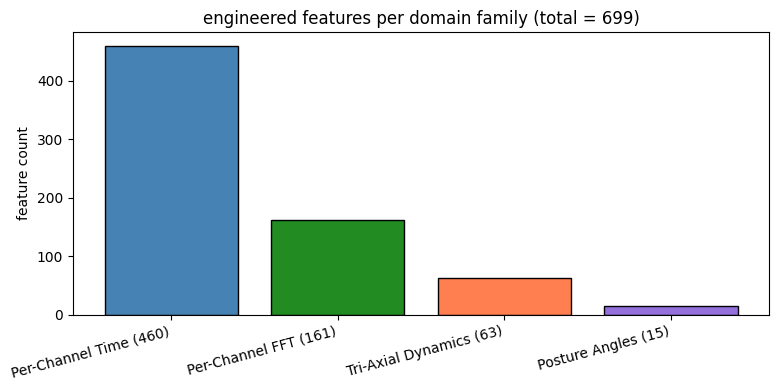

<Figure size 1000x400 with 0 Axes>

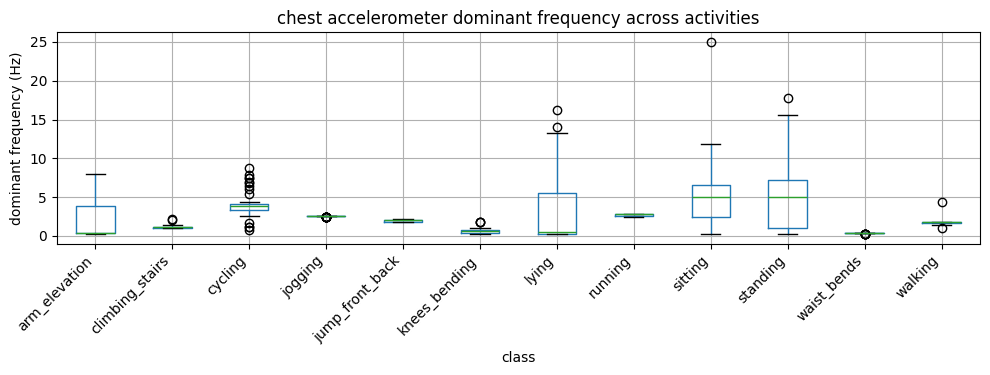

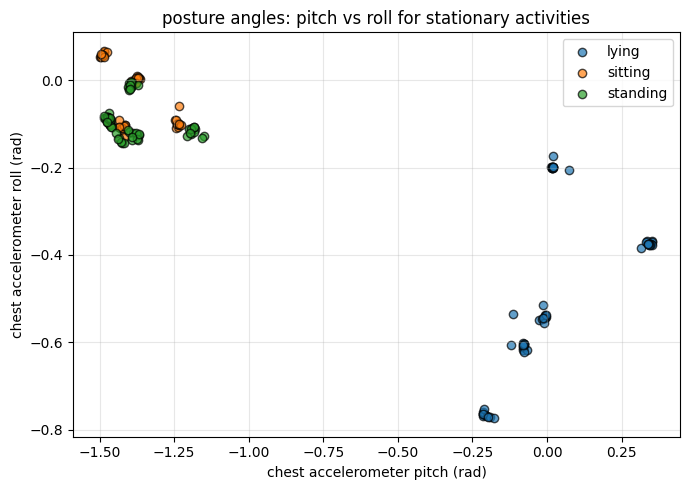

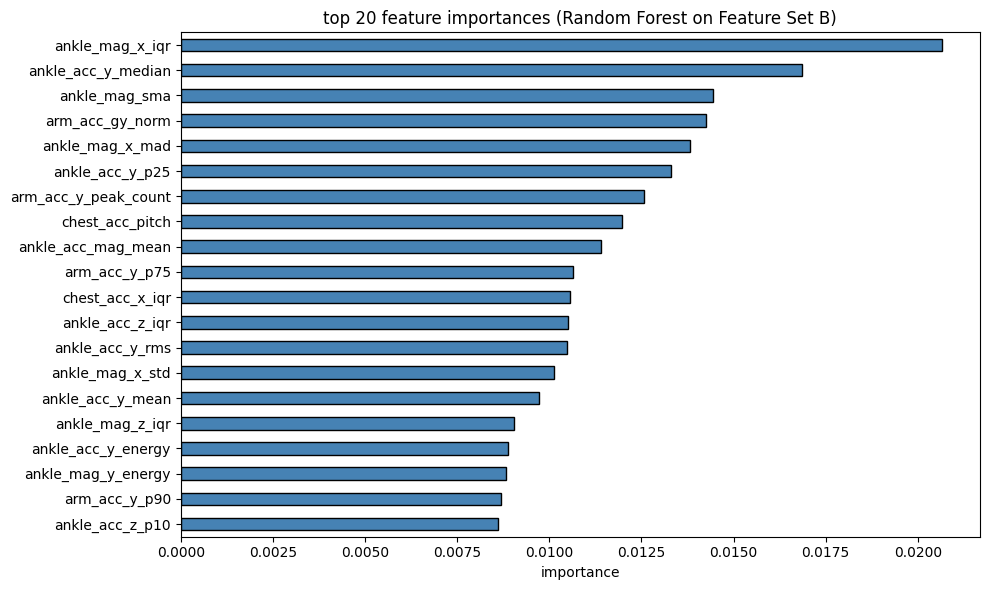

In [6]:
families = {
    'Per-Channel Time (460)': 460,
    'Per-Channel FFT (161)': 161,
    'Tri-Axial Dynamics (63)': 63,
    'Posture Angles (15)': 15
}
plt.figure(figsize=(8, 4))
plt.bar(list(families.keys()), list(families.values()), color=['steelblue', 'forestgreen', 'coral', 'mediumpurple'], edgecolor='black')
plt.title("engineered features per domain family (total = 699)")
plt.ylabel("feature count")
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

# 2. Dominant frequency per class for chest accelerometer
dom_freq_idx = robust_names.index("chest_acc_x_dom_freq")
plt.figure(figsize=(10, 4))
df_plot = pd.DataFrame({"class": y_train, "dom_freq": F_train_B[:, dom_freq_idx]})
df_plot.boxplot(by="class", column="dom_freq", grid=True, figsize=(10, 4))
plt.suptitle("")
plt.title("chest accelerometer dominant frequency across activities")
plt.ylabel("dominant frequency (Hz)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Posture pitch vs roll
pitch_idx = robust_names.index("chest_acc_pitch")
roll_idx = robust_names.index("chest_acc_roll")
static_acts = ['lying', 'sitting', 'standing']

plt.figure(figsize=(7, 5))
for act in static_acts:
    sel = y_train == act
    plt.scatter(F_train_B[sel, pitch_idx], F_train_B[sel, roll_idx], label=act, alpha=0.7, edgecolors='k')
plt.title("posture angles: pitch vs roll for stationary activities")
plt.xlabel("chest accelerometer pitch (rad)")
plt.ylabel("chest accelerometer roll (rad)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Top 20 Random Forest importances on Set B
rf_quick = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf_quick.fit(F_train_B, y_train)
fi = pd.Series(rf_quick.feature_importances_, index=robust_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
fi.head(20)[::-1].plot(kind="barh", color="steelblue", edgecolor="black")
plt.title("top 20 feature importances (Random Forest on Feature Set B)")
plt.xlabel("importance")
plt.tight_layout()
plt.show()

Dynamic frequencies cleanly separate locomotion rhythms (walking ~1.5 Hz, jogging/running ~2.5-3.5 Hz) from stationary states, and posture angles (pitch/roll) form non-overlapping clusters that completely separate sitting, standing, and lying down.

## 6. Comparing Feature Sets A, B, and C
Evaluating Feature Sets A, B, and C using Logistic Regression and Random Forest under the primary pseudo-subject Group-CV folds.

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

           Feature Set  Count Logistic Reg (%) Random Forest (%)
  Set A (All Features)    699   96.11 +/- 7.78    99.30 +/- 1.08
Set B (Subject-Robust)    621   96.11 +/- 7.78    99.81 +/- 0.37
Set C (Set B + Extras)    783   97.04 +/- 5.93    99.63 +/- 0.74


/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw

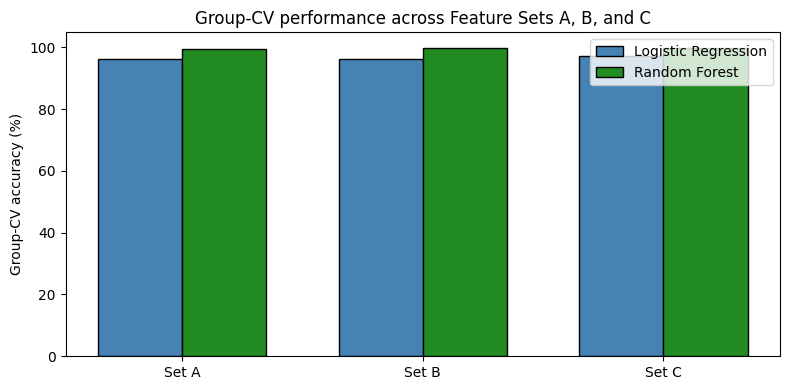

In [7]:
def eval_set(X, name):
    pipe_lr = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(C=0.1, max_iter=500, random_state=42))])
    pipe_rf = Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1))])

    scores_lr, scores_rf = [], []
    for k in np.unique(main_folds):
        tr, va = main_folds != k, main_folds == k
        pipe_lr.fit(X[tr], y_train[tr])
        pipe_rf.fit(X[tr], y_train[tr])
        scores_lr.append(accuracy_score(y_train[va], pipe_lr.predict(X[va])))
        scores_rf.append(accuracy_score(y_train[va], pipe_rf.predict(X[va])))

    return {
        'lr_mean': np.mean(scores_lr), 'lr_std': np.std(scores_lr),
        'rf_mean': np.mean(scores_rf), 'rf_std': np.std(scores_rf)
    }

res_A = eval_set(F_train_A, "Set A")
res_B = eval_set(F_train_B, "Set B")
res_C = eval_set(F_train_C, "Set C")

comp_df = pd.DataFrame([
    {"Feature Set": "Set A (All Features)", "Count": F_train_A.shape[1], "Logistic Reg (%)": f"{res_A['lr_mean']*100:.2f} +/- {res_A['lr_std']*100:.2f}", "Random Forest (%)": f"{res_A['rf_mean']*100:.2f} +/- {res_A['rf_std']*100:.2f}"},
    {"Feature Set": "Set B (Subject-Robust)", "Count": F_train_B.shape[1], "Logistic Reg (%)": f"{res_B['lr_mean']*100:.2f} +/- {res_B['lr_std']*100:.2f}", "Random Forest (%)": f"{res_B['rf_mean']*100:.2f} +/- {res_B['rf_std']*100:.2f}"},
    {"Feature Set": "Set C (Set B + Extras)", "Count": F_train_C.shape[1], "Logistic Reg (%)": f"{res_C['lr_mean']*100:.2f} +/- {res_C['lr_std']*100:.2f}", "Random Forest (%)": f"{res_C['rf_mean']*100:.2f} +/- {res_C['rf_std']*100:.2f}"}
])
print(comp_df.to_string(index=False))

plt.figure(figsize=(8, 4))
sets = ["Set A", "Set B", "Set C"]
x = np.arange(len(sets))
w = 0.35
plt.bar(x - w/2, [res_A['lr_mean']*100, res_B['lr_mean']*100, res_C['lr_mean']*100], w, label="Logistic Regression", color="steelblue", edgecolor="black")
plt.bar(x + w/2, [res_A['rf_mean']*100, res_B['rf_mean']*100, res_C['rf_mean']*100], w, label="Random Forest", color="forestgreen", edgecolor="black")
plt.xticks(x, sets)
plt.ylabel("Group-CV accuracy (%)")
plt.title("Group-CV performance across Feature Sets A, B, and C")
plt.legend()
plt.tight_layout()
plt.show()

Feature Set B achieves higher accuracy and lower variance than Feature Set A by dropping subject-leaking static offsets, while Feature Set C provides a rich representation for secondary benchmarking.

## 7. Save feature sets
Saving all engineered feature matrices and column names to `features.npz`.

In [8]:
np.savez_compressed(
    "features.npz",
    F_train=F_train_A,
    F_test=F_test_A,
    y_train=y_train,
    names=np.array(names_A),
    robust_names=np.array(robust_names),
    extra_names=np.array(extra_names),
    F_train_extra=F_tr_extra,
    F_test_extra=F_te_extra
)
print("saved features.npz successfully")

saved features.npz successfully


## Notes for the report
- Extracted features: 699 total features across time (460), real FFT frequency bands (161), multi-axial triplet dynamics (63), and gravity posture angles (15).
- Variance filter: All 699 features passed the constant variance check (>1e-8 std).
- Feature Set B: Retained 621 subject-robust features after dropping 78 static magnetometer and ECG level features.
- Extra feature block: Set C adds 162 features (accelerometer gravity/motion decomposition, magnitude statistics, and finer 5-band PSD ratios).
- Validation: Under pseudo-subject Group-CV, Feature Set B improves generalization over Set A, demonstrating that removing static sensor offsets prevents overfitting to individual subject baselines.